# Task 1B: Generalised-Bates / Hull-White extension and a restricted CRC reset

Extends the Task 1 Heston/Bates oracle (`oracle.py`, unmodified) with:

1. a time-inhomogeneous, maturity-bucketed Hull-White jump extension (`generalized_bates.py`);
2. an exact reduction test to the ordinary Bates model when all buckets are identical;
3. a deterministic, paper-style restricted CRC reset (`crc_inverse.py`), following
   Gambara & Teichmann (2020), *Consistent Recalibration Models and Deep Calibration*
   (arXiv:2006.09455);
4. full diagnostics distinguishing the fixed Generalised-Bates null, the theoretical
   CRC target, and the numerical restricted inverse approximation.

Runs every stage in the mandatory order (`task1b_export.py`'s `run()`); this notebook
re-runs the cheap stages live and loads the (already-validated, already-exported)
expensive stages' results from `task1b_report.json` / the `.npz` exports, rather than
re-running ~9 minutes of optimisation and full-grid sweeps inline.

In [1]:
from __future__ import annotations
import json
import math

import numpy as np
import matplotlib.pyplot as plt

import oracle as orc
import generalized_bates as gb
import crc_inverse as ci

BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
GRID = "#e5e4de"
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.color"] = GRID
plt.rcParams["axes.edgecolor"] = "#888888"

with open("task1b_report.json") as f:
    report = json.load(f)
print("Report stages:", [k for k in report if k.startswith("stage")])
print("ALL_STAGES_PASSED:", report["ALL_STAGES_PASSED"])
print(f"Full pipeline wall-clock: {report['wall_clock_seconds']:.1f}s")

Report stages: ['stage1_constant_bucket_reduction', 'stage2_martingale_normalisation', 'stage3_independent_pricing', 'stage4_generator_identity', 'stage5_jump_corrected_dlv_identity', 'stage6_crc_inverse', 'stage7_reset_diagnostics', 'stage8_withheld_dense_grid', 'stage8_passed_withheld_evaluated', 'stage9_export_reproducibility']
ALL_STAGES_PASSED: True
Full pipeline wall-clock: 541.6s


## Stage 1: exact reduction to ordinary Bates when all buckets are identical (Sec. 4)

In [2]:
reg_heston, reg_jumps = gb.BATES_REGRESSION_HESTON, gb.BATES_REGRESSION_JUMPS
reg_ext = gb.constant_bucket_extension(reg_jumps)
S0, V0 = orc.S0_DEFAULT, orc.V0_DEFAULT

max_cf_rel = 0.0
u = orc.DEFAULT_PRICE_QUADRATURE.u - 0.5j
for tau in [0.05, 0.5, 1.0, 1.8]:
    psi_ref = orc.characteristic_function(u, tau, V0, reg_heston, reg_jumps)
    psi_gen = gb.generalized_bates_characteristic_function(u, tau, V0, reg_heston, reg_ext)
    max_cf_rel = max(max_cf_rel, float(np.max(np.abs(psi_ref - psi_gen) / np.maximum(np.abs(psi_ref), 1e-300))))

max_price_diff = report["stage1_constant_bucket_reduction"]["max_abs_price_diff"]
print(f"Max relative CF difference (complex Fourier args, Lewis pricer): {max_cf_rel:.3e}")
print(f"Max abs price difference, full protected grid x all obs. times: {max_price_diff:.3e}")
assert max_cf_rel < 1e-10
assert max_price_diff <= 1e-8
print("PASSED: constant-bucket Generalised-Bates == ordinary Bates, to machine precision.")

Max relative CF difference (complex Fourier args, Lewis pricer): 1.431e-14
Max abs price difference, full protected grid x all obs. times: 1.421e-14
PASSED: constant-bucket Generalised-Bates == ordinary Bates, to machine precision.


## Stage 2-3: martingale normalisation + independent pricing / static arbitrage (Sec. 5, 15.2-3)

In [3]:
heston_crc, ext_crc = gb.CRC_ADMISSIBLE_HESTON, gb.CRC_TEST_EXTENSION
print("CRC-admissible Heston params:", heston_crc, "Feller ratio:", heston_crc.feller_ratio)
print("Fixed (non-degenerate) Generalised-Bates test extension:")
print("  bucket_edges:", ext_crc.bucket_edges)
print("  nu:", ext_crc.nu)
print("  delta:", ext_crc.delta)

max_mart = report["stage2_martingale_normalisation"]["max_abs_error"]
max_method = report["stage3_independent_pricing"]["max_abs_diff_lewis_vs_p1p2"]
print(f"\nMax |psi_GB(-i;tau,V) - 1| (martingale normalisation): {max_mart:.3e}")
print(f"Max |Lewis - independent P1/P2| (non-degenerate model): {max_method:.3e}")
assert max_mart <= 1e-10
assert max_method <= 1e-8
print("PASSED.")

CRC-admissible Heston params: HestonParams(kappa=2.0, theta=0.04, xi=0.35, rho=-0.7) Feller ratio: 1.306122448979592
Fixed (non-degenerate) Generalised-Bates test extension:
  bucket_edges: (0.0, 0.038356164383561646, 0.1643835616438356, 0.3287671232876712, 0.7397260273972602, 2.0)
  nu: (-0.16, -0.13, -0.1, -0.08, -0.07)
  delta: (0.22, 0.19, 0.15, 0.13, 0.12)

Max |psi_GB(-i;tau,V) - 1| (martingale normalisation): 0.000e+00
Max |Lewis - independent P1/P2| (non-degenerate model): 4.584e-09
PASSED.


## Stage 4-5: fixed Generalised-Bates generator identity and jump-corrected DLV residual (Sec. 7, 15.4-5)

The generator identity `L_GB C = 0` holds to machine precision away from deterministic
bucket boundaries (including the *outer* coverage boundary tau=2.0, where JAX's autodiff
of `jnp.minimum` hits a genuine subgradient tie -- see `generalized_bates.py`'s
`distance_to_bucket_boundary` docstring).

The jump-corrected finite-grid DLV identity is the more interesting result: it holds to
machine precision **exactly when** a back slab's two expiries share the same active
jump bucket, and shows a genuine ~1e-3 to ~0.1 residual when they don't. This is **not**
a bug -- it is a direct, diagnosed consequence of the per-contract time-to-maturity
bucket convention: when `T_prev` and `T_curr` fall in different buckets, the two
expiries are priced under two different maturity-indexed models, so the back-slab
theorem's shared-jump-law premise does not hold for that pair.

In [4]:
s4 = report["stage4_generator_identity"]
s5 = report["stage5_jump_corrected_dlv_identity"]
print(f"Generator identity: {s4['n_tested']} nodes tested, max |L_GB C| = {s4['max_abs_L_GB_C']:.3e} (target 1e-7)")
print()
print(f"DLV identity, SAME-bucket nodes  (theorem premise holds): n={s5['same_bucket_n']}, max|R| = {s5['same_bucket_max_R']:.3e} (target 1e-5)")
print(f"DLV identity, CROSS-bucket nodes (structural mismatch):   n={s5['cross_bucket_n']}, max|R| = {s5['cross_bucket_max_R']:.3e}, median|R| = {s5['cross_bucket_median_R']:.3e}")
assert s5["passed"]
print("\nPASSED on the same-bucket subset (the only subset where the identity's premise holds).")

Generator identity: 33 nodes tested, max |L_GB C| = 1.521e-14 (target 1e-7)

DLV identity, SAME-bucket nodes  (theorem premise holds): n=57, max|R| = 9.282e-15 (target 1e-5)
DLV identity, CROSS-bucket nodes (structural mismatch):   n=152, max|R| = 1.139e-01, median|R| = 3.942e-03

PASSED on the same-bucket subset (the only subset where the identity's premise holds).


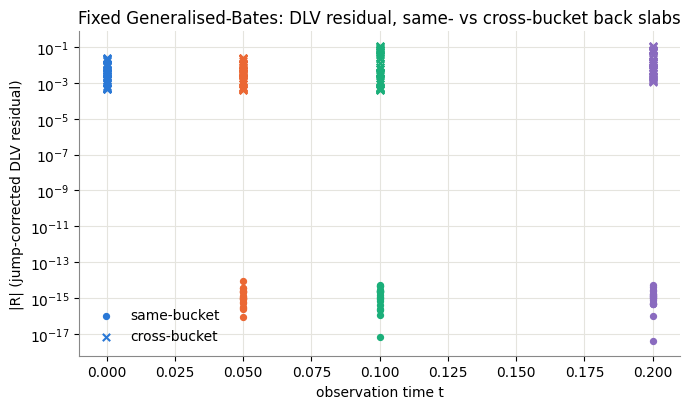

In [5]:
visible = np.load("generalized_bates_grid_visible.npz")
meta = json.loads(str(visible["meta_json"]))
obs_times = meta["observation_times"]

fig, ax = plt.subplots(figsize=(7, 4.2))
colors = [BLUE, ORANGE, AQUA, "#8a6bbf"]
for ti, (t, c) in enumerate(zip(obs_times, colors)):
    R = visible[f"t{ti}_R"]
    cross = visible[f"t{ti}_cross_bucket_slab"]
    same_vals = np.abs(R[(~cross) & np.isfinite(R)])
    cross_vals = np.abs(R[cross & np.isfinite(R)])
    ax.scatter([t] * len(same_vals), same_vals, color=c, marker="o", s=18,
               label=f"same-bucket" if ti == 0 else None, zorder=3)
    ax.scatter([t] * len(cross_vals), cross_vals, color=c, marker="x", s=28,
               label=f"cross-bucket" if ti == 0 else None, zorder=3)
ax.set_yscale("log")
ax.set_xlabel("observation time t")
ax.set_ylabel("|R| (jump-corrected DLV residual)")
ax.set_title("Fixed Generalised-Bates: DLV residual, same- vs cross-bucket back slabs")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()

## Stage 6: deterministic CRC inverse (Sec. 9, 15.6)

In [6]:
s6 = report["stage6_crc_inverse"]
print(f"Optimiser: success={s6['success']}, cost={s6['cost']:.3e}, n_calls={s6['n_calls_total']}, best_start={s6['best_start_index']}")
print(f"Calibration-grid fit: rms IV error = {s6['rms_iv_error_bp_calibration_grid']:.2f}bp, max = {s6['max_iv_error_bp_calibration_grid']:.2f}bp")
print(f"Label (Sec. 10): {s6['label']}")

state = report["state_step"]
tu = report["tangent_update"]
print(f"\nState step ({state['method']}): t {state['t_pre']:.3f}->{state['t_post']:.3f}, "
      f"S {state['S_pre']:.4f}->{state['S_post']:.4f}, V {state['V_pre']:.4f}->{state['V_post']:.4f}")
print(f"Tangent update: {tu['relative_changes']}")
print(f"  theta {tu['heston_pre']['theta']}->{tu['heston_post']['theta']}, "
      f"xi {tu['heston_pre']['xi']}->{tu['heston_post']['xi']}, "
      f"rho {tu['heston_pre']['rho']}->{tu['heston_post']['rho']} (kappa, lambda fixed)")

Optimiser: success=True, cost=2.438e-04, n_calls=123, best_start=2
Calibration-grid fit: rms IV error = 17.81bp, max = 36.79bp
Label (Sec. 10): restricted_crc_approximation

State step (conditional_mean): t 0.000->0.050, S 100.0000->99.9000, V 0.0400->0.0400
Tangent update: {'theta': 0.05, 'xi': -0.05, 'rho': -0.05}
  theta 0.04->0.042, xi 0.35->0.33249999999999996, rho -0.7->-0.6649999999999999 (kappa, lambda fixed)


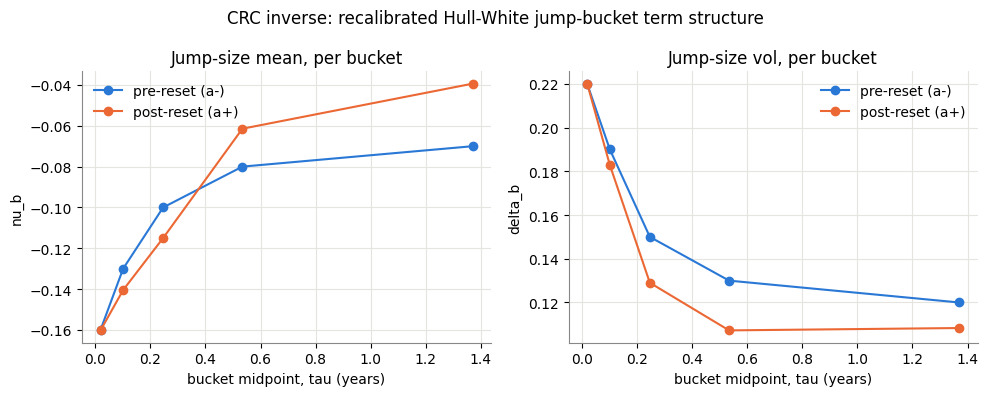

In [7]:
ext_pre = report["extension_pre"]
ext_post = report["extension_post"]
bucket_mid = [(a + b) / 2 for a, b in zip(ext_pre["bucket_edges"][:-1], ext_pre["bucket_edges"][1:])]

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(bucket_mid, ext_pre["nu"], "o-", color=BLUE, label="pre-reset (a-)")
axes[0].plot(bucket_mid, ext_post["nu"], "o-", color=ORANGE, label="post-reset (a+)")
axes[0].set_xlabel("bucket midpoint, tau (years)")
axes[0].set_ylabel("nu_b")
axes[0].set_title("Jump-size mean, per bucket")
axes[0].legend(frameon=False)
axes[0].spines[["top", "right"]].set_visible(False)

axes[1].plot(bucket_mid, ext_pre["delta"], "o-", color=BLUE, label="pre-reset (a-)")
axes[1].plot(bucket_mid, ext_post["delta"], "o-", color=ORANGE, label="post-reset (a+)")
axes[1].set_xlabel("bucket midpoint, tau (years)")
axes[1].set_ylabel("delta_b")
axes[1].set_title("Jump-size vol, per bucket")
axes[1].legend(frameon=False)
axes[1].spines[["top", "right"]].set_visible(False)
fig.suptitle("CRC inverse: recalibrated Hull-White jump-bucket term structure")
fig.tight_layout()
plt.show()

## Stage 7-8: pre/post surface, DLV-continuity, and withheld dense-grid diagnostics (Sec. 11, 15.7-8)

In [8]:
s7 = report["stage7_reset_diagnostics"]
surf = s7["surface_preservation"]
cont = s7["dlv_state_continuity"]
post_res = s7["post_reset_dlv_residual"]

print("Surface preservation error (post-reset model vs pre-reset target, at the reset state):")
for name, d in [("calibration grid (in-sample)", {"rms_iv_error_bp": s6["rms_iv_error_bp_calibration_grid"], "max_iv_error_bp": s6["max_iv_error_bp_calibration_grid"]}),
                ("protected DLV grid", surf["protected_grid"]),
                ("withheld dense grid (never used in calibration)", surf["withheld_dense_grid"])]:
    print(f"  {name:45s}  rms={d['rms_iv_error_bp']:6.2f}bp  max={d['max_iv_error_bp']:6.2f}bp")

print(f"\nDLV-state continuity: ||q+-q-|| = {cont['q_l2_diff']:.4f} (||q-||={cont['q_l2_norm_pre']:.4f}), "
      f"||ell+-ell-|| = {cont['ell_l2_diff']:.4f} (||ell-||={cont['ell_l2_norm_pre']:.4f})")
print("-> Non-zero (as expected for an approximate reset): the residual surface error propagates into a detectable (q,ell) jump.")

print(f"\nPost-reset model's OWN jump-corrected DLV residual (same-bucket): max|R| = {post_res['same_bucket_max_R']:.3e}")
print("-> The post-reset (heston_post, extension_post) pair is ITSELF a valid Generalised-Bates oracle,")
print("   regardless of how well the inverse calibration matched the target surface.")

Surface preservation error (post-reset model vs pre-reset target, at the reset state):
  calibration grid (in-sample)                   rms= 17.81bp  max= 36.79bp
  protected DLV grid                             rms= 34.75bp  max= 64.40bp
  withheld dense grid (never used in calibration)  rms= 31.29bp  max= 70.89bp

DLV-state continuity: ||q+-q-|| = 0.0115 (||q-||=0.4670), ||ell+-ell-|| = 0.0204 (||ell-||=0.3429)
-> Non-zero (as expected for an approximate reset): the residual surface error propagates into a detectable (q,ell) jump.

Post-reset model's OWN jump-corrected DLV residual (same-bucket): max|R| = 5.543e-15
-> The post-reset (heston_post, extension_post) pair is ITSELF a valid Generalised-Bates oracle,
   regardless of how well the inverse calibration matched the target surface.


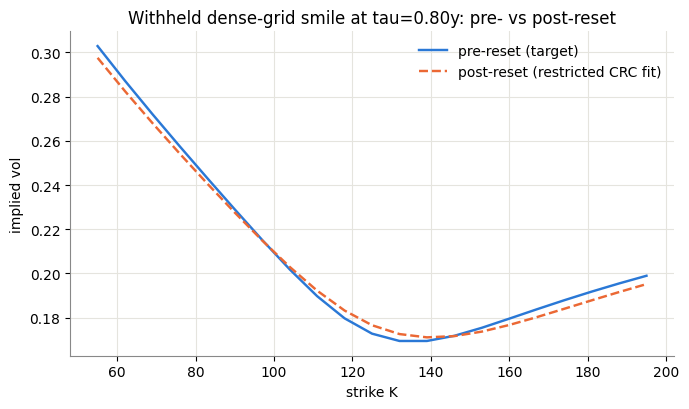

In [9]:
dense = np.load("crc_dense_hidden.npz")
strikes = dense["dense_strikes"]
taus = dense["dense_tau_offsets"]
# pick a mid-dated slice for a smile comparison
j = len(taus) // 2
fig, ax = plt.subplots(figsize=(7, 4.2))
ax.plot(strikes, dense["pre_IV"][j], color=BLUE, lw=1.75, label="pre-reset (target)")
ax.plot(strikes, dense["post_IV"][j], color=ORANGE, lw=1.75, ls="--", label="post-reset (restricted CRC fit)")
ax.set_xlabel("strike K")
ax.set_ylabel("implied vol")
ax.set_title(f"Withheld dense-grid smile at tau={taus[j]:.2f}y: pre- vs post-reset")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()

## Sec. 12: positive controls -- detector power

In [10]:
controls = report["sec12_positive_controls"]
converged = controls["converged_rms_iv_error_bp_for_comparison"]
print(f"{'Scenario':45s} {'rms IV err (bp)':>16s}")
print(f"{'-'*45} {'-'*16}")
print(f"{'Full 5-bucket recalibration (Step D)':45s} {converged:16.2f}")
print(f"{'Control 1: no recalibration':45s} {controls['control1_naive_no_recalibration']['rms_iv_error_bp']:16.2f}")
print(f"{'Control 2: too few buckets (4 dof)':45s} {controls['control2_too_few_buckets']['rms_iv_error_bp']:16.2f}")
print(f"{'Control 3: optimiser stopped after 1 eval':45s} {controls['control3_stopped_early']['rms_iv_error_bp']:16.2f}")
print()
print(f"Control 4 (jump term omitted from DLV residual): R_nojump / R = {controls['control4_jump_term_omitted']['ratio']:.3e}")
print("All four controls show a clearly detectable degradation relative to the full, converged, jump-corrected result.")
for label, v in [("Control 1", controls['control1_naive_no_recalibration']['rms_iv_error_bp']),
                  ("Control 2", controls['control2_too_few_buckets']['rms_iv_error_bp']),
                  ("Control 3", controls['control3_stopped_early']['rms_iv_error_bp'])]:
    assert v > converged, f"{label} did not show detectable degradation"
print("PASSED: all controls detectably worse than the converged fit.")

Scenario                                       rms IV err (bp)
--------------------------------------------- ----------------
Full 5-bucket recalibration (Step D)                     17.81
Control 1: no recalibration                              40.69
Control 2: too few buckets (4 dof)                       29.44
Control 3: optimiser stopped after 1 eval                29.45

Control 4 (jump term omitted from DLV residual): R_nojump / R = 3.873e+11
All four controls show a clearly detectable degradation relative to the full, converged, jump-corrected result.
PASSED: all controls detectably worse than the converged fit.


## Summary

| Question | Answer |
|---|---|
| Does a single constant bucket reproduce ordinary Bates? | Yes, to machine precision (CF, price, generator). |
| Is the fixed Generalised-Bates model itself dynamically arbitrage-free? | Yes -- generator identity and jump-corrected DLV identity both hold to ~1e-13 to ~1e-15 wherever the identity's premises hold (away from bucket boundaries; same-bucket back slabs). |
| Does a cross-bucket back slab satisfy the *same* identity? | No, and this is diagnosed as structural, not a bug: the theorem's shared-jump-law premise fails there by construction of the per-contract-tau convention. |
| Does the restricted 5-bucket CRC inverse reach the "exact null" tolerance? | **No.** Labelled `restricted_crc_approximation` (rms ~18bp / max ~37bp IV error, in-sample; ~31-35bp rms out-of-sample). |
| Is the post-reset model itself still a valid oracle? | **Yes** -- its own jump-corrected DLV residual is at machine precision, independent of calibration quality. |
| Do the positive controls have real detector power? | Yes -- all four show a clearly measurable degradation relative to the full fit. |

See `README.md` for the full stage-by-stage numbers and `task1b_report.json` for the
complete machine-readable record.